# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 03: Iris Normalization

### Objective

This notebook performs **iris normalization** using the **Daugman rubber sheet model**, following the segmentation results produced in Notebook 02.

The notebook must:

1. Read the segmentation metadata produced by Notebook 02.
2. Load the raw grayscale image together with the detected pupil and limbus boundaries.
3. Load the eyelid, eyelash, and reflection occlusion masks produced during segmentation.
4. Apply the rubber sheet model to unwrap the circular iris region between the pupil and limbus boundaries into a fixed-size rectangular representation.
5. Normalize the corresponding occlusion information into a **noise mask** in the same rectangular coordinate system.
6. Save the normalized iris images and their noise masks without altering the raw dataset or the Notebook 02 outputs.
7. Save normalization metadata for Notebook 04 and later stages.
8. Produce visual quality-control previews and coverage statistics.

### Important boundary of this notebook

This notebook performs **geometric normalization only**.

It does **not** perform:

- CLAHE, histogram equalization, gamma correction, denoising, or sharpening,
- feature extraction or iris code encoding,
- quality-score filtering,
- few-shot split creation,
- model training.

Those are handled by later notebooks. In particular, **image enhancement is handled by Notebook 04**, which will operate directly on the normalized images produced here.

### Method

Circular iris &rarr; Rectangular iris, via the **rubber sheet model** (Daugman, 1993, 2004). Every point on the iris annulus, bounded on the inside by the pupil boundary and on the outside by the limbus boundary, is remapped to a fixed-size polar coordinate grid `(r, \u03b8)`, independent of pupil dilation, iris size, and imaging distance.


## 1. Research rationale

The rubber sheet model remaps every pixel of the iris annulus from Cartesian image coordinates `(x, y)` into non-concentric polar coordinates `(r, \u03b8)`:

```text
I(x(r, \u03b8), y(r, \u03b8))  --->  I(r, \u03b8)

x(r, \u03b8) = (1 - r) * x_p(\u03b8) + r * x_l(\u03b8)
y(r, \u03b8) = (1 - r) * y_p(\u03b8) + r * y_l(\u03b8)
```

where:

- `\u03b8 \u2208 [0, 2\u03c0)` is the angular coordinate, sampled at a fixed angular resolution,
- `r \u2208 [0, 1]` is the normalized radial coordinate, sampled at a fixed radial resolution,
- `(x_p(\u03b8), y_p(\u03b8))` is a point on the pupil boundary at angle `\u03b8`,
- `(x_l(\u03b8), y_l(\u03b8))` is a point on the limbus boundary at angle `\u03b8`.

Because the pupil and limbus circles detected in Notebook 02 are not required to share the same center, this formulation naturally handles non-concentric pupil/limbus geometry, which is the normal case in real eye images.

The result is a fixed-size rectangular texture in which the same relative position always corresponds to the same anatomical location on the iris, regardless of pupil dilation or original image resolution. This is what makes rubber-sheet-normalized iris images comparable across subjects and across acquisitions.

```text
Raw eye image + pupil/limbus boundaries (Notebook 02)
        |
        +----> sample along radial rays from pupil boundary to limbus boundary
        |
        v
Fixed-size normalized iris texture (this notebook)
        |
        v
Normalized noise mask (occlusion carried into the same coordinate system)
```

Occlusions detected in Notebook 02 (eyelid, eyelash, reflection, and any pixel outside the final usable iris mask) are not discarded. They are remapped through the same geometric transform into a **noise mask** aligned with the normalized image, so that later notebooks can identify which normalized pixels are unreliable without having to repeat segmentation.


In [1]:
# ============================================================
# 2. Imports
# ============================================================

from pathlib import Path
import json
import math
import random
import warnings

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from IPython.display import display

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

OpenCV version: 5.0.0
NumPy version: 2.4.6
Pandas version: 3.0.5


In [2]:
# ============================================================
# 3. Project paths
# ============================================================

NOTEBOOK_DIR = Path.cwd()

if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Run this notebook from "
        "the project root or the notebooks directory."
    )

RAW_DATA_DIR = PROJECT_ROOT / "datasets" / "raw"

NOTEBOOK02_RESULTS_DIR = PROJECT_ROOT / "results" / "iris_segmentation"
SEGMENTATION_METADATA_PATH = NOTEBOOK02_RESULTS_DIR / "segmentation_metadata.csv"

RESULTS_DIR = PROJECT_ROOT / "results" / "iris_normalization"

NORMALIZED_DIR = RESULTS_DIR / "normalized"
NOISE_MASK_DIR = RESULTS_DIR / "noise_masks"
PREVIEW_DIR = RESULTS_DIR / "previews"

NORMALIZED_DIR.mkdir(parents=True, exist_ok=True)
NOISE_MASK_DIR.mkdir(parents=True, exist_ok=True)
PREVIEW_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Notebook 02 segmentation metadata:", SEGMENTATION_METADATA_PATH)
print("Notebook 03 results:", RESULTS_DIR)

Project root: E:\Research\LargeScale_Synthetic_Iris_Generation
Notebook 02 segmentation metadata: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_segmentation\segmentation_metadata.csv
Notebook 03 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_normalization


## 4. Load Notebook 02 metadata

Notebook 02 hands off `segmentation_metadata.csv`, which records, for every raw image:

- identity/eye/dataset labels,
- the detected pupil circle (`pupil_cx`, `pupil_cy`, `pupil_radius`),
- the detected limbus circle (`limbus_cx`, `limbus_cy`, `limbus_radius`),
- paths to the final usable iris mask and the individual eyelid/eyelash/reflection masks,
- a `success` flag and a `reason` for any detection failure.

Only rows with `success == True` and valid pupil/limbus geometry can be normalized. Rows that failed segmentation are retained in the output metadata with an explicit failure reason rather than being silently dropped.


In [3]:
# ============================================================
# 4. Load Notebook 02 metadata
# ============================================================

if not SEGMENTATION_METADATA_PATH.exists():
    raise FileNotFoundError(
        f"Notebook 02 segmentation metadata was not found at: "
        f"{SEGMENTATION_METADATA_PATH}\n"
        "Run 02_Iris_Segmentation.ipynb first."
    )

segmentation_metadata = pd.read_csv(SEGMENTATION_METADATA_PATH)

required_columns = {
    "dataset",
    "identity",
    "eye",
    "filename",
    "original_path",
    "success",
    "pupil_cx",
    "pupil_cy",
    "pupil_radius",
    "limbus_cx",
    "limbus_cy",
    "limbus_radius",
    "iris_mask_path",
    "eyelid_mask_path",
    "eyelash_mask_path",
    "reflection_mask_path",
}

missing = required_columns.difference(segmentation_metadata.columns)

if missing:
    raise ValueError(
        f"Notebook 02 metadata is missing required columns: {sorted(missing)}"
    )

print("Segmentation metadata shape:", segmentation_metadata.shape)
print(
    "Successful segmentations available for normalization:",
    int(segmentation_metadata["success"].sum()),
    "/",
    len(segmentation_metadata),
)

display(segmentation_metadata.head())

Segmentation metadata shape: (22180, 30)
Successful segmentations available for normalization: 22176 / 22180


,dataset,identity,eye,filename,original_path,success,reason,pupil_cx,pupil_cy,pupil_radius,...,usable_iris_area_px,usable_fraction,eyelid_area_px,eyelash_area_px,reflection_area_px,segmented_path,iris_mask_path,eyelid_mask_path,eyelash_mask_path,reflection_mask_path
0,CASIA-Iris-Thousand,0,L,S5000L00.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,True,ok,265.0,259.0,33.0,...,23371,0.808210,1455,909,0,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...
1,CASIA-Iris-Thousand,0,L,S5000L01.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,True,ok,284.0,250.0,34.0,...,22813,0.788913,1655,1183,0,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...
2,CASIA-Iris-Thousand,0,L,S5000L02.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,True,ok,555.0,248.0,42.0,...,21951,0.777935,0,379,108,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...
3,CASIA-Iris-Thousand,0,L,S5000L03.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,True,ok,338.0,153.0,91.0,...,40150,0.575801,776,1120,192,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...
4,CASIA-Iris-Thousand,0,L,S5000L04.jpg,E:\Research\LargeScale_Synthetic_Iris_Generati...,True,ok,633.0,423.0,44.0,...,54885,0.892947,1090,1514,392,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...,E:\Research\LargeScale_Synthetic_Iris_Generati...


## 5. Configuration

The normalized image size is fixed at `NORM_RADIAL_RES x NORM_ANGULAR_RES` (rows x columns). `64 x 512` is a common working resolution in the iris-recognition literature: fine enough to preserve texture detail while keeping downstream processing (Notebook 04 enhancement, feature extraction) computationally manageable.

`START_ANGLE` fixes the angular origin (`\u03b8 = 0`) at the 3 o'clock position, matching the trigonometric convention used for the pupil/limbus circles in Notebook 02. Angles increase counter-clockwise as `\u03b8` increases, following standard image-coordinate trigonometry (`y` axis pointing down).

As in Notebook 02, `MAX_IMAGES_PER_DATASET` can be set to a small integer for an initial test run before processing the full dataset.


In [4]:
# ============================================================
# 5. Configuration
# ============================================================

MAX_IMAGES_PER_DATASET = None   # e.g. 20 for an initial test; None = all
SAVE_PREVIEWS = True
PREVIEW_COUNT_PER_DATASET = 12

# Fixed output size of the normalized (rubber-sheet) iris texture.
NORM_RADIAL_RES = 64     # rows    -> radial samples, pupil (r=0) to limbus (r=1)
NORM_ANGULAR_RES = 512   # columns -> angular samples, theta in [0, 2*pi)

# Angular origin, in radians. 0.0 = 3 o'clock position.
START_ANGLE = 0.0

print("Configuration loaded.")
print(f"Normalized image size: {NORM_RADIAL_RES} x {NORM_ANGULAR_RES} (rows x cols)")

Configuration loaded.
Normalized image size: 64 x 512 (rows x cols)


## 6. Utility functions

`safe_read_gray` reuses the same convention as Notebook 02: the raw image is read as `uint8` grayscale and is never overwritten. `safe_read_mask` reads a mask file saved by Notebook 02 and falls back to an all-zero mask (no occlusion) if the file is missing, so a missing individual mask does not stop the whole pipeline.


In [5]:
# ============================================================
# 6. Utility functions
# ============================================================

def safe_read_gray(path):
    '''Read an image as uint8 grayscale.'''
    path = Path(path)
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        raise ValueError(f"Unable to read image: {path}")

    if image.dtype != np.uint8:
        image = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    return image


def safe_read_mask(path, shape):
    '''Read a mask saved by Notebook 02. Falls back to an all-zero mask.'''
    if path is None or (isinstance(path, float) and np.isnan(path)):
        return np.zeros(shape, dtype=np.uint8)

    path = Path(str(path))

    if not path.exists():
        return np.zeros(shape, dtype=np.uint8)

    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        return np.zeros(shape, dtype=np.uint8)

    if mask.shape != shape:
        mask = cv2.resize(
            mask,
            (shape[1], shape[0]),
            interpolation=cv2.INTER_NEAREST,
        )

    return mask


def circle_from_row(row, prefix):
    '''Build a {cx, cy, radius} dict from metadata columns, or None if missing.'''
    cx = row.get(f"{prefix}_cx")
    cy = row.get(f"{prefix}_cy")
    radius = row.get(f"{prefix}_radius")

    if pd.isna(cx) or pd.isna(cy) or pd.isna(radius) or radius <= 0:
        return None

    return {"cx": float(cx), "cy": float(cy), "radius": float(radius)}

## 7. Rubber sheet mapping construction

For a fixed angular resolution, the pupil-boundary point and the limbus-boundary point are computed at every sampled angle `\u03b8`. For a fixed radial resolution, each output row linearly interpolates between the pupil point (`r = 0`) and the limbus point (`r = 1`).

This produces two coordinate maps, `map_x` and `map_y`, of shape `(NORM_RADIAL_RES, NORM_ANGULAR_RES)`, which are then used with `cv2.remap` to sample the source image in a single vectorized operation rather than a Python-level pixel loop.


In [6]:
# ============================================================
# 7. Rubber sheet mapping construction
# ============================================================

def build_rubber_sheet_maps(
    pupil,
    limbus,
    radial_res=NORM_RADIAL_RES,
    angular_res=NORM_ANGULAR_RES,
    start_angle=START_ANGLE,
):
    '''Build (map_x, map_y) coordinate maps for the Daugman rubber sheet model.

    map_x, map_y have shape (radial_res, angular_res). Row index 0 corresponds
    to the pupil boundary (r = 0); the last row corresponds to the limbus
    boundary (r = 1). Column index corresponds to angle theta, sampled
    uniformly over [start_angle, start_angle + 2*pi).
    '''

    theta = start_angle + np.linspace(
        0.0, 2.0 * np.pi, angular_res, endpoint=False
    )

    cos_t = np.cos(theta)
    sin_t = np.sin(theta)

    pupil_x = pupil["cx"] + pupil["radius"] * cos_t
    pupil_y = pupil["cy"] + pupil["radius"] * sin_t

    limbus_x = limbus["cx"] + limbus["radius"] * cos_t
    limbus_y = limbus["cy"] + limbus["radius"] * sin_t

    r_frac = np.linspace(0.0, 1.0, radial_res).reshape(-1, 1)

    map_x = (1.0 - r_frac) * pupil_x.reshape(1, -1) + r_frac * limbus_x.reshape(1, -1)
    map_y = (1.0 - r_frac) * pupil_y.reshape(1, -1) + r_frac * limbus_y.reshape(1, -1)

    return map_x.astype(np.float32), map_y.astype(np.float32)

## 8. Noise mask construction

Before normalization, the individual occlusion masks produced in Notebook 02 (eyelid, eyelash, reflection) are combined with the complement of the final usable iris mask into a single **invalid-pixel mask** in the original image coordinates. A pixel is marked invalid if it falls outside the accepted usable iris region, or inside any detected occlusion.

This invalid mask is carried through the *same* rubber-sheet coordinate transform as the intensity image, using **nearest-neighbor** interpolation so that mask values remain binary. The result is a normalized noise mask that tells later notebooks, pixel-for-pixel, which parts of the normalized iris texture are unreliable and should be down-weighted or excluded, without needing to repeat segmentation.


In [7]:
# ============================================================
# 8. Noise mask construction
# ============================================================

def build_invalid_mask(iris_mask, eyelid_mask, eyelash_mask, reflection_mask):
    '''Combine occlusions and the non-usable region into one invalid mask.

    255 = invalid / unreliable pixel, 0 = valid usable iris pixel.
    '''
    invalid = np.zeros_like(iris_mask, dtype=np.uint8)

    invalid[iris_mask == 0] = 255
    invalid[eyelid_mask > 0] = 255
    invalid[eyelash_mask > 0] = 255
    invalid[reflection_mask > 0] = 255

    return invalid

## 9. Complete normalization function

This function runs the entire Notebook 03 pipeline for one image:

```text
raw grayscale image + pupil circle + limbus circle
        |
        v
rubber sheet coordinate maps (map_x, map_y)
        |
        +----> cv2.remap(image, ..., INTER_LINEAR)   -> normalized iris texture
        |
        +----> cv2.remap(invalid_mask, ..., INTER_NEAREST) -> normalized noise mask
```

`valid_fraction` reports the proportion of the normalized texture that is *not* marked as noise, giving a quick per-image quality indicator that mirrors the `usable_fraction` computed in Notebook 02.


In [8]:
# ============================================================
# 9. Complete normalization function
# ============================================================

def normalize_iris(
    gray,
    pupil,
    limbus,
    iris_mask,
    eyelid_mask,
    eyelash_mask,
    reflection_mask,
    radial_res=NORM_RADIAL_RES,
    angular_res=NORM_ANGULAR_RES,
    start_angle=START_ANGLE,
):
    '''Run the complete rubber-sheet normalization pipeline for one image.'''

    if pupil is None or limbus is None:
        return {
            "success": False,
            "reason": "missing_pupil_or_limbus",
            "normalized_image": None,
            "normalized_noise_mask": None,
            "valid_fraction": np.nan,
        }

    if limbus["radius"] <= pupil["radius"]:
        return {
            "success": False,
            "reason": "non_positive_iris_annulus",
            "normalized_image": None,
            "normalized_noise_mask": None,
            "valid_fraction": np.nan,
        }

    map_x, map_y = build_rubber_sheet_maps(
        pupil,
        limbus,
        radial_res=radial_res,
        angular_res=angular_res,
        start_angle=start_angle,
    )

    normalized_image = cv2.remap(
        gray,
        map_x,
        map_y,
        interpolation=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0,
    )

    invalid_mask = build_invalid_mask(
        iris_mask,
        eyelid_mask,
        eyelash_mask,
        reflection_mask,
    )

    normalized_noise_mask = cv2.remap(
        invalid_mask,
        map_x,
        map_y,
        interpolation=cv2.INTER_NEAREST,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=255,
    )

    valid_fraction = float(1.0 - (normalized_noise_mask > 0).mean())

    return {
        "success": True,
        "reason": None,
        "normalized_image": normalized_image,
        "normalized_noise_mask": normalized_noise_mask,
        "valid_fraction": valid_fraction,
        "map_x": map_x,
        "map_y": map_y,
    }

## 10. Single-image test

Before processing the complete datasets, normalize one successfully segmented image and inspect the result. If the rubber sheet mapping looks wrong here (torn texture, wrong orientation, degenerate annulus), it must be fixed before running the complete dataset.


In [9]:
# ============================================================
# 10. Single-image test
# ============================================================

successful_rows = segmentation_metadata[segmentation_metadata["success"] == True]

if len(successful_rows) == 0:
    raise RuntimeError(
        "No successful segmentations were found in the Notebook 02 metadata. "
        "Run 02_Iris_Segmentation.ipynb with a configuration that produces "
        "at least some successful detections before continuing."
    )

sample_row = successful_rows.iloc[0]

sample_gray = safe_read_gray(sample_row["original_path"])

sample_pupil = circle_from_row(sample_row, "pupil")
sample_limbus = circle_from_row(sample_row, "limbus")

sample_iris_mask = safe_read_mask(sample_row["iris_mask_path"], sample_gray.shape)
sample_eyelid_mask = safe_read_mask(sample_row["eyelid_mask_path"], sample_gray.shape)
sample_eyelash_mask = safe_read_mask(sample_row["eyelash_mask_path"], sample_gray.shape)
sample_reflection_mask = safe_read_mask(sample_row["reflection_mask_path"], sample_gray.shape)

sample_result = normalize_iris(
    sample_gray,
    sample_pupil,
    sample_limbus,
    sample_iris_mask,
    sample_eyelid_mask,
    sample_eyelash_mask,
    sample_reflection_mask,
)

print("Sample:", sample_row["original_path"])
print("Pupil:", sample_pupil)
print("Limbus:", sample_limbus)
print("Success:", sample_result["success"])
print("Valid fraction:", sample_result["valid_fraction"])

Sample: E:\Research\LargeScale_Synthetic_Iris_Generation\datasets\raw\CASIA-Iris-Thousand\CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\S5000L00.jpg
Pupil: {'cx': 265.0, 'cy': 259.0, 'radius': 33.0}
Limbus: {'cx': 265.0, 'cy': 259.0, 'radius': 96.0}
Success: True
Valid fraction: 0.90447998046875


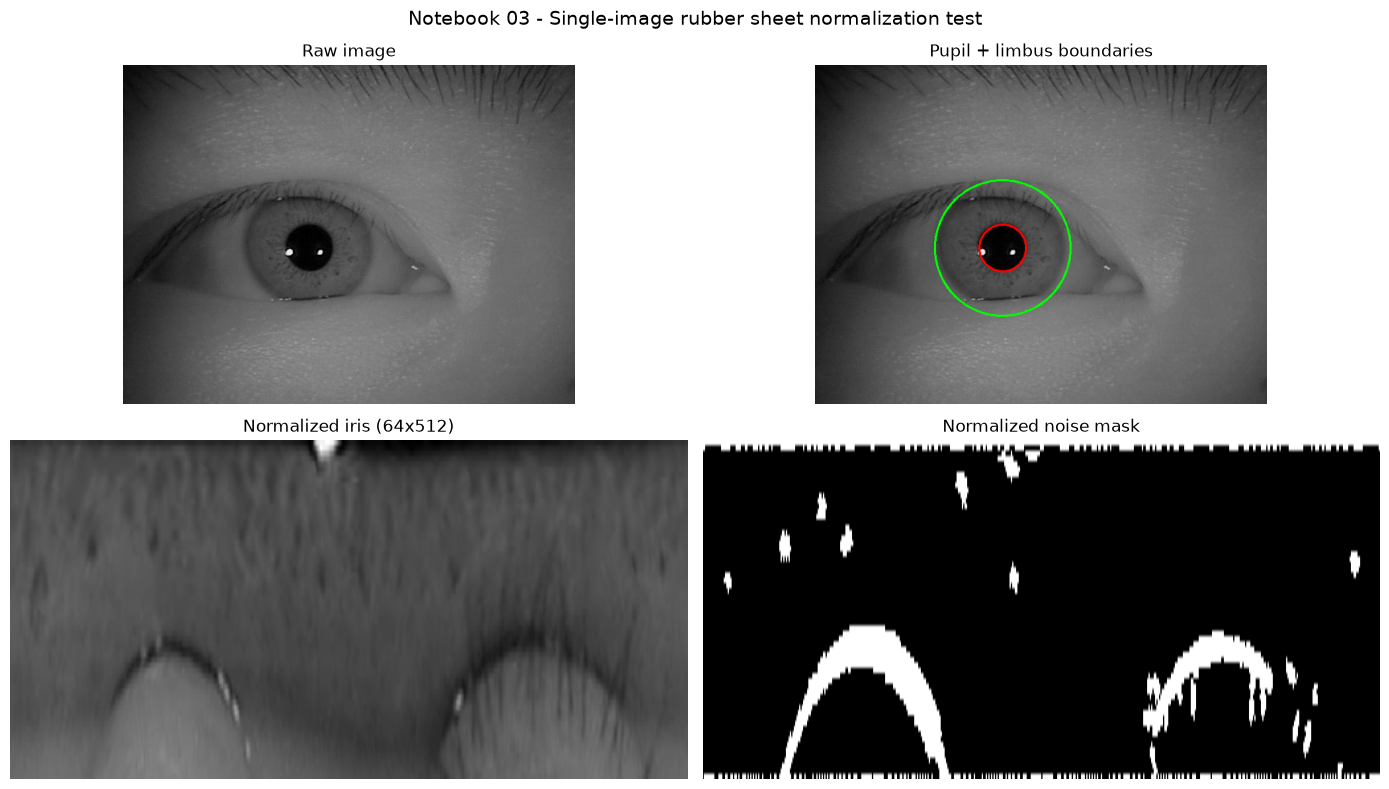

In [10]:
# ============================================================
# 11. Visualize the single-image normalization
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].imshow(sample_gray, cmap="gray")
axes[0, 0].set_title("Raw image")
axes[0, 0].axis("off")

vis = cv2.cvtColor(sample_gray, cv2.COLOR_GRAY2RGB)
cv2.circle(
    vis,
    (int(round(sample_pupil["cx"])), int(round(sample_pupil["cy"]))),
    int(round(sample_pupil["radius"])),
    (255, 0, 0),
    2,
)
cv2.circle(
    vis,
    (int(round(sample_limbus["cx"])), int(round(sample_limbus["cy"]))),
    int(round(sample_limbus["radius"])),
    (0, 255, 0),
    2,
)
axes[0, 1].imshow(vis)
axes[0, 1].set_title("Pupil + limbus boundaries")
axes[0, 1].axis("off")

axes[1, 0].imshow(sample_result["normalized_image"], cmap="gray", aspect="auto")
axes[1, 0].set_title(f"Normalized iris ({NORM_RADIAL_RES}x{NORM_ANGULAR_RES})")
axes[1, 0].axis("off")

axes[1, 1].imshow(sample_result["normalized_noise_mask"], cmap="gray", aspect="auto")
axes[1, 1].set_title("Normalized noise mask")
axes[1, 1].axis("off")

plt.suptitle("Notebook 03 - Single-image rubber sheet normalization test", fontsize=14)
plt.tight_layout()
plt.show()

## 12. Build output paths

Outputs are kept separate from the raw dataset and from the Notebook 02 outputs.

```text
results/
└── iris_normalization/
    ├── normalized/
    │   ├── CASIA-Iris-Thousand/
    │   └── IITD/
    ├── noise_masks/
    │   ├── CASIA-Iris-Thousand/
    │   └── IITD/
    ├── previews/
    └── normalization_metadata.csv
```

The Notebook 02 outputs are never overwritten.


In [11]:
# ============================================================
# 12. Output path helpers
# ============================================================

def dataset_safe_name(dataset):
    return (
        str(dataset)
        .replace("/", "_")
        .replace("\\\\", "_")
        .replace(" ", "_")
    )


def identity_safe_name(identity):
    if pd.isna(identity):
        return "unknown_identity"
    return str(identity).replace("/", "_").replace("\\\\", "_")


def eye_safe_name(eye):
    if pd.isna(eye):
        return "UNKNOWN"
    return str(eye).replace("/", "_")


def make_output_paths(row):
    dataset_name = dataset_safe_name(row["dataset"])
    identity_name = identity_safe_name(row["identity"])
    eye_name = eye_safe_name(row["eye"])
    stem = Path(row["filename"]).stem

    normalized_path = (
        NORMALIZED_DIR /
        dataset_name /
        identity_name /
        eye_name /
        f"{stem}_normalized.png"
    )

    noise_mask_path = (
        NOISE_MASK_DIR /
        dataset_name /
        identity_name /
        eye_name /
        f"{stem}_noise_mask.png"
    )

    return {
        "normalized_path": normalized_path,
        "noise_mask_path": noise_mask_path,
    }


def ensure_parent_directories(paths):
    for path in paths.values():
        path.parent.mkdir(parents=True, exist_ok=True)

## 13. Process the datasets

Every row from Notebook 02 is carried forward, including rows that failed segmentation. Rows with `success == False` in the segmentation metadata are recorded with `reason = "segmentation_failed"` and are not normalized, so downstream notebooks can see the complete accounting from raw image to normalized texture without recomputing anything.


In [12]:
# ============================================================
# 13. Select rows to process
# ============================================================

rows_to_process = []

for dataset_name, df in segmentation_metadata.groupby("dataset", dropna=False):
    df = df.copy()

    if MAX_IMAGES_PER_DATASET is not None:
        df = df.sample(
            n=min(MAX_IMAGES_PER_DATASET, len(df)),
            random_state=RANDOM_SEED,
        )

    rows_to_process.append(df)

processing_metadata = pd.concat(
    rows_to_process,
    ignore_index=True,
)

print("Rows selected for normalization stage:", len(processing_metadata))
display(processing_metadata["dataset"].value_counts())

Rows selected for normalization stage: 22180


dataset
CASIA-Iris-Thousand    20000
IITD                    2180
Name: count, dtype: int64

In [2]:
# ============================================================
# 14. Run normalization and save outputs
# ============================================================

records = []

total = len(processing_metadata)

for idx, row in processing_metadata.iterrows():

    record = {
        "dataset": row["dataset"],
        "identity": row["identity"],
        "eye": row["eye"],
        "filename": row["filename"],
        "original_path": row["original_path"],
        "segmented_path": row.get("segmented_path"),
        "success": False,
        "reason": None,
        "valid_fraction": np.nan,
        "radial_resolution": NORM_RADIAL_RES,
        "angular_resolution": NORM_ANGULAR_RES,
        "normalized_path": None,
        "noise_mask_path": None,
    }

    if not bool(row["success"]):
        record["reason"] = "segmentation_failed"
        records.append(record)
        continue

    try:
        gray = safe_read_gray(row["original_path"])

        pupil = circle_from_row(row, "pupil")
        limbus = circle_from_row(row, "limbus")

        iris_mask = safe_read_mask(row["iris_mask_path"], gray.shape)
        eyelid_mask = safe_read_mask(row["eyelid_mask_path"], gray.shape)
        eyelash_mask = safe_read_mask(row["eyelash_mask_path"], gray.shape)
        reflection_mask = safe_read_mask(row["reflection_mask_path"], gray.shape)

        result = normalize_iris(
            gray,
            pupil,
            limbus,
            iris_mask,
            eyelid_mask,
            eyelash_mask,
            reflection_mask,
        )

        record["success"] = result["success"]
        record["reason"] = result["reason"]
        record["valid_fraction"] = result["valid_fraction"]

        if result["success"]:
            output_paths = make_output_paths(row)
            ensure_parent_directories(output_paths)

            cv2.imwrite(
                str(output_paths["normalized_path"]),
                result["normalized_image"],
            )
            cv2.imwrite(
                str(output_paths["noise_mask_path"]),
                result["normalized_noise_mask"],
            )

            record["normalized_path"] = str(output_paths["normalized_path"])
            record["noise_mask_path"] = str(output_paths["noise_mask_path"])

    except Exception as e:
        record["success"] = False
        record["reason"] = f"exception: {e}"

    records.append(record)

    if (idx + 1) % 200 == 0 or (idx + 1) == total:
        print(f"Processed {idx + 1} / {total} images")

normalization_metadata = pd.DataFrame(records)

print("Normalization complete.")
print("Successful normalizations:", int(normalization_metadata["success"].sum()), "/", len(normalization_metadata))

NameError: name 'processing_metadata' is not defined

## 15. Save normalization metadata

The requested hand-off file for Notebook 04 is `normalization_metadata.csv`, saved inside `results/iris_normalization/`.


In [14]:
# ============================================================
# 15. Save normalization metadata
# ============================================================

NORMALIZATION_METADATA_PATH = RESULTS_DIR / "normalization_metadata.csv"

normalization_metadata.to_csv(
    NORMALIZATION_METADATA_PATH,
    index=False,
)

print("Saved:", NORMALIZATION_METADATA_PATH)

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_normalization\normalization_metadata.csv


## 16. Normalization statistics

These statistics are diagnostic. They do not replace a dedicated image-quality assessment, which belongs to a later notebook.


In [15]:
# ============================================================
# 16. Normalization statistics
# ============================================================

total_images = len(normalization_metadata)
successful = int(normalization_metadata["success"].sum())

summary = {
    "total_images": total_images,
    "successful_normalizations": successful,
    "failed_normalizations": total_images - successful,
    "success_rate_percent": (
        100 * successful / total_images
        if total_images else 0.0
    ),
    "mean_valid_fraction": (
        normalization_metadata.loc[
            normalization_metadata["success"],
            "valid_fraction"
        ].mean()
    ),
    "median_valid_fraction": (
        normalization_metadata.loc[
            normalization_metadata["success"],
            "valid_fraction"
        ].median()
    ),
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["metric", "value"],
)

display(summary_df)

print("\\nFailure reasons:")
display(
    normalization_metadata.loc[
        ~normalization_metadata["success"],
        "reason"
    ].value_counts(dropna=False)
)

,metric,value
0,total_images,22180.000000
1,successful_normalizations,22176.000000
2,failed_normalizations,4.000000
3,success_rate_percent,99.981966
4,mean_valid_fraction,0.854162
5,median_valid_fraction,0.879654


\nFailure reasons:


reason
segmentation_failed    4
Name: count, dtype: int64

## 17. Dataset-wise normalization summary

In [16]:
# ============================================================
# 17. Dataset-wise normalization summary
# ============================================================

dataset_normalization_summary = (
    normalization_metadata
    .groupby("dataset")
    .agg(
        total_images=("filename", "count"),
        successful=("success", "sum"),
        mean_valid_fraction=("valid_fraction", "mean"),
        median_valid_fraction=("valid_fraction", "median"),
    )
    .reset_index()
)

dataset_normalization_summary["success_rate_percent"] = (
    100 *
    dataset_normalization_summary["successful"] /
    dataset_normalization_summary["total_images"]
)

display(dataset_normalization_summary)

dataset_summary_path = RESULTS_DIR / "normalization_summary_by_dataset.csv"

dataset_normalization_summary.to_csv(
    dataset_summary_path,
    index=False,
)

print("Saved:", dataset_summary_path)

,dataset,total_images,successful,mean_valid_fraction,median_valid_fraction,success_rate_percent
0,CASIA-Iris-Thousand,20000,20000,0.874578,0.884369,100.000000
1,IITD,2180,2176,0.666515,0.684158,99.816514


Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_normalization\normalization_summary_by_dataset.csv


## 18. Visual quality-control previews

A normalization notebook should not be judged from CSV statistics alone. The following previews display, for a sample of successfully normalized images per dataset:

1. raw image with pupil/limbus boundaries,
2. normalized iris texture,
3. normalized noise mask,
4. normalized texture with the noise mask overlaid.

The previews are saved to `results/iris_normalization/previews/`.


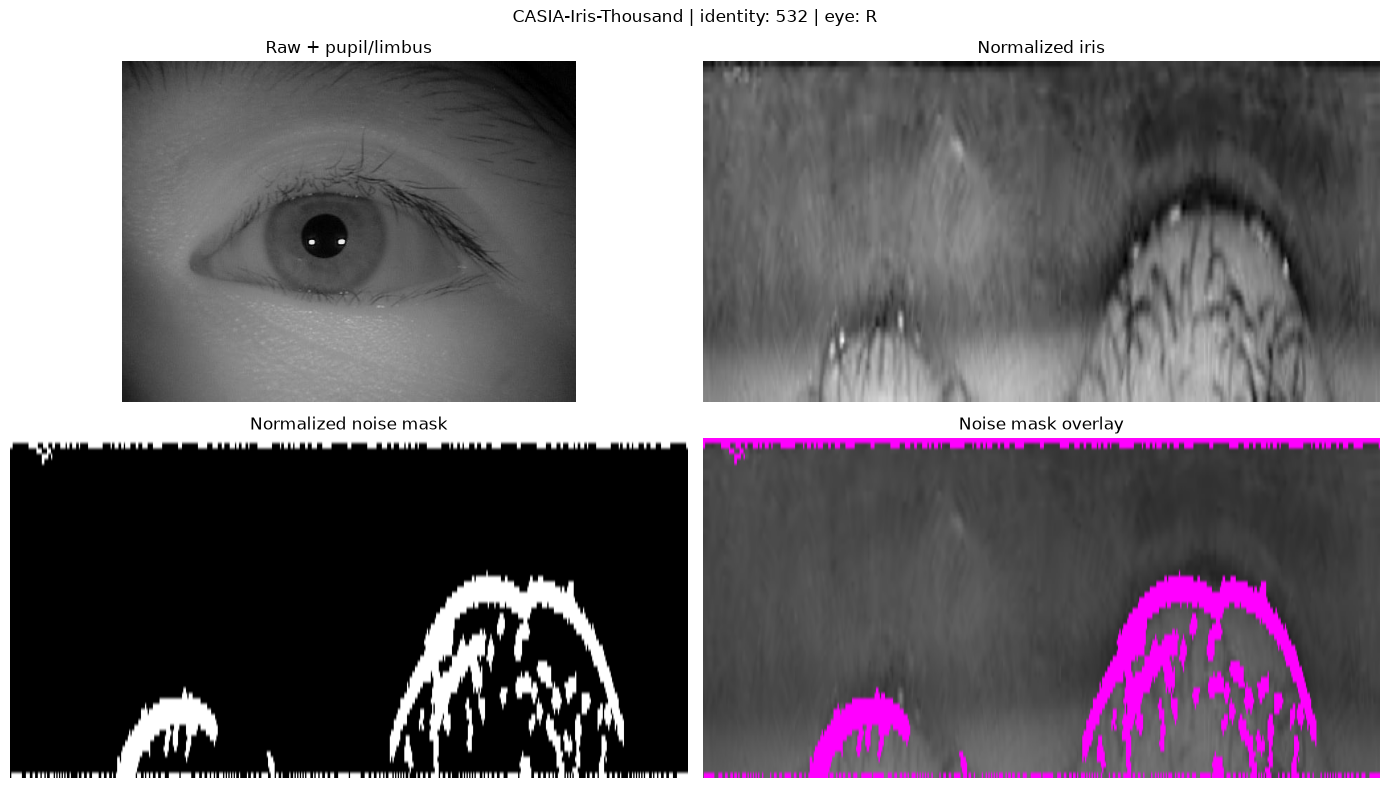

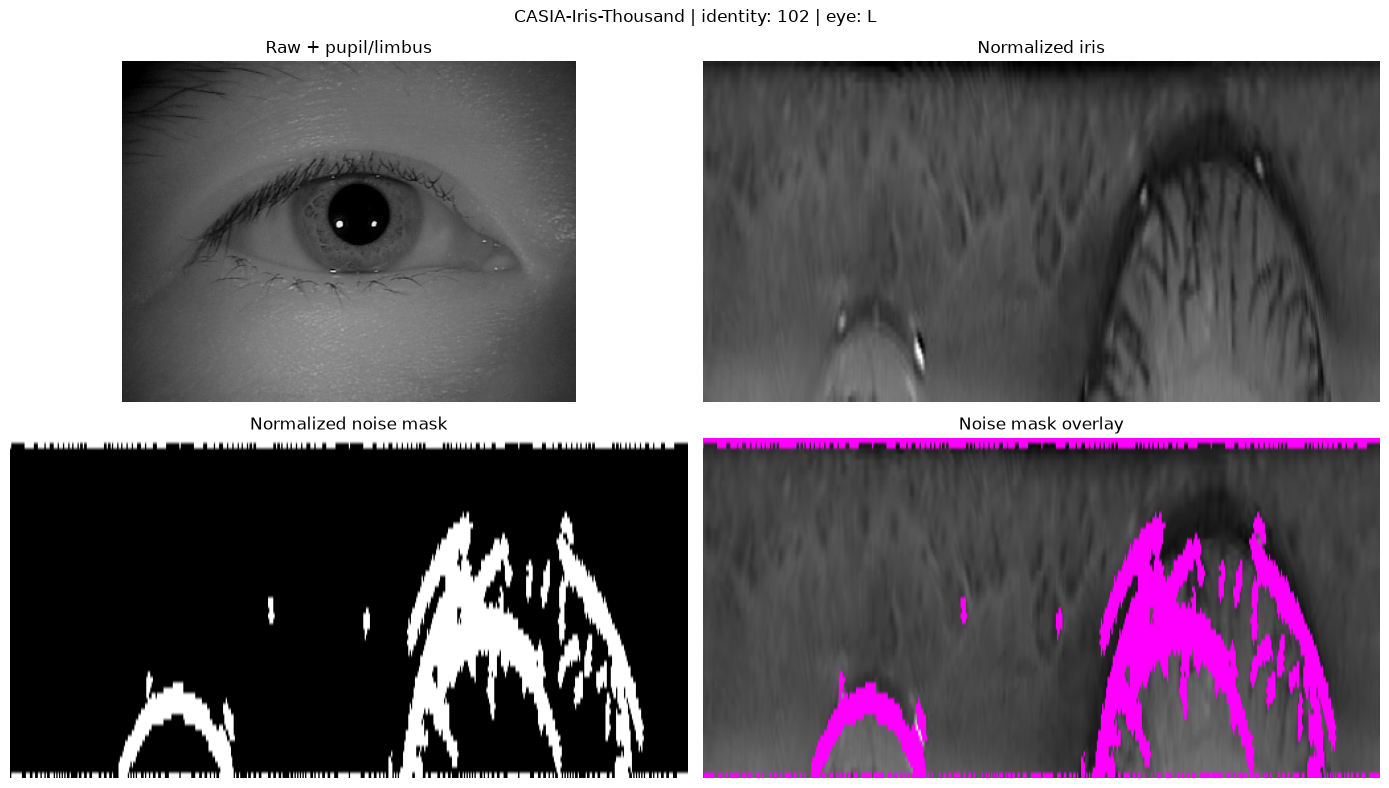

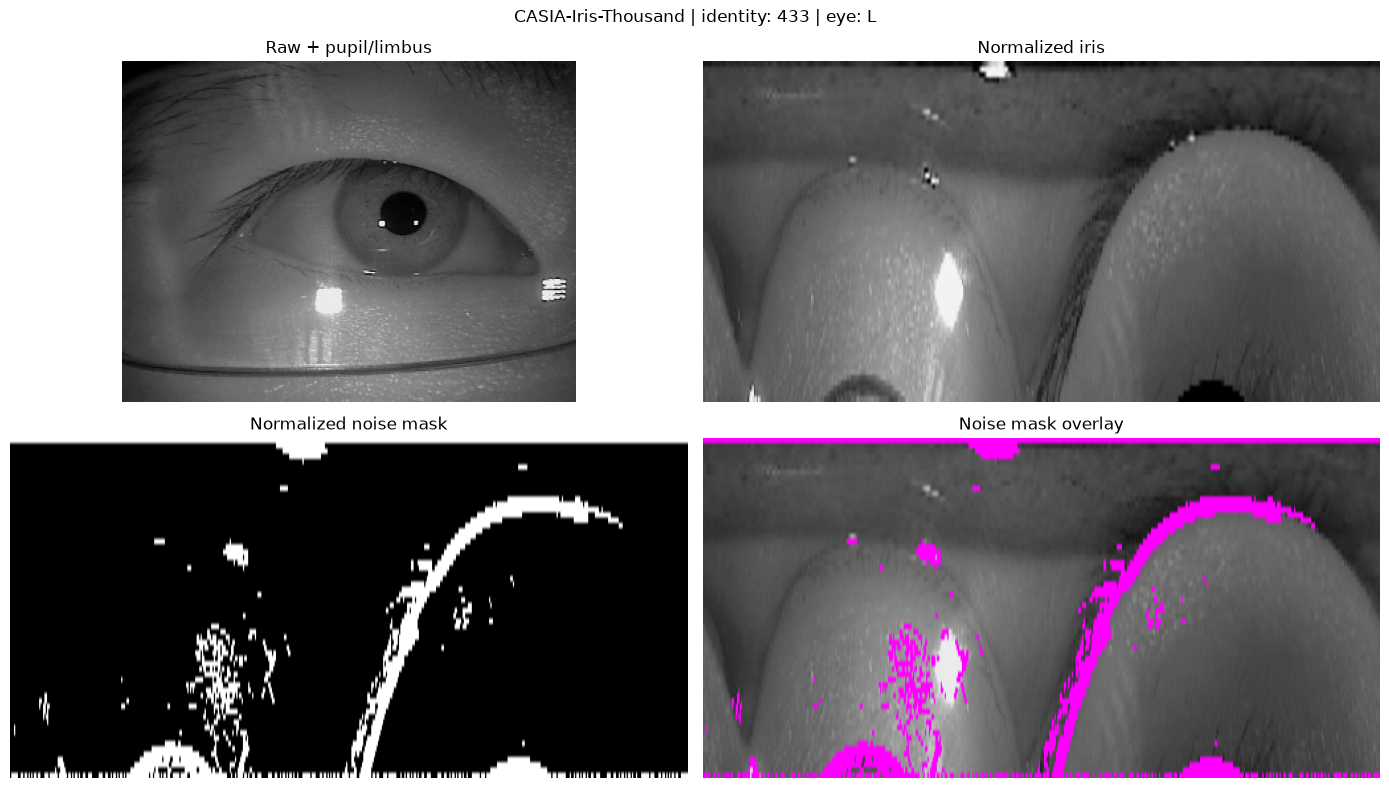

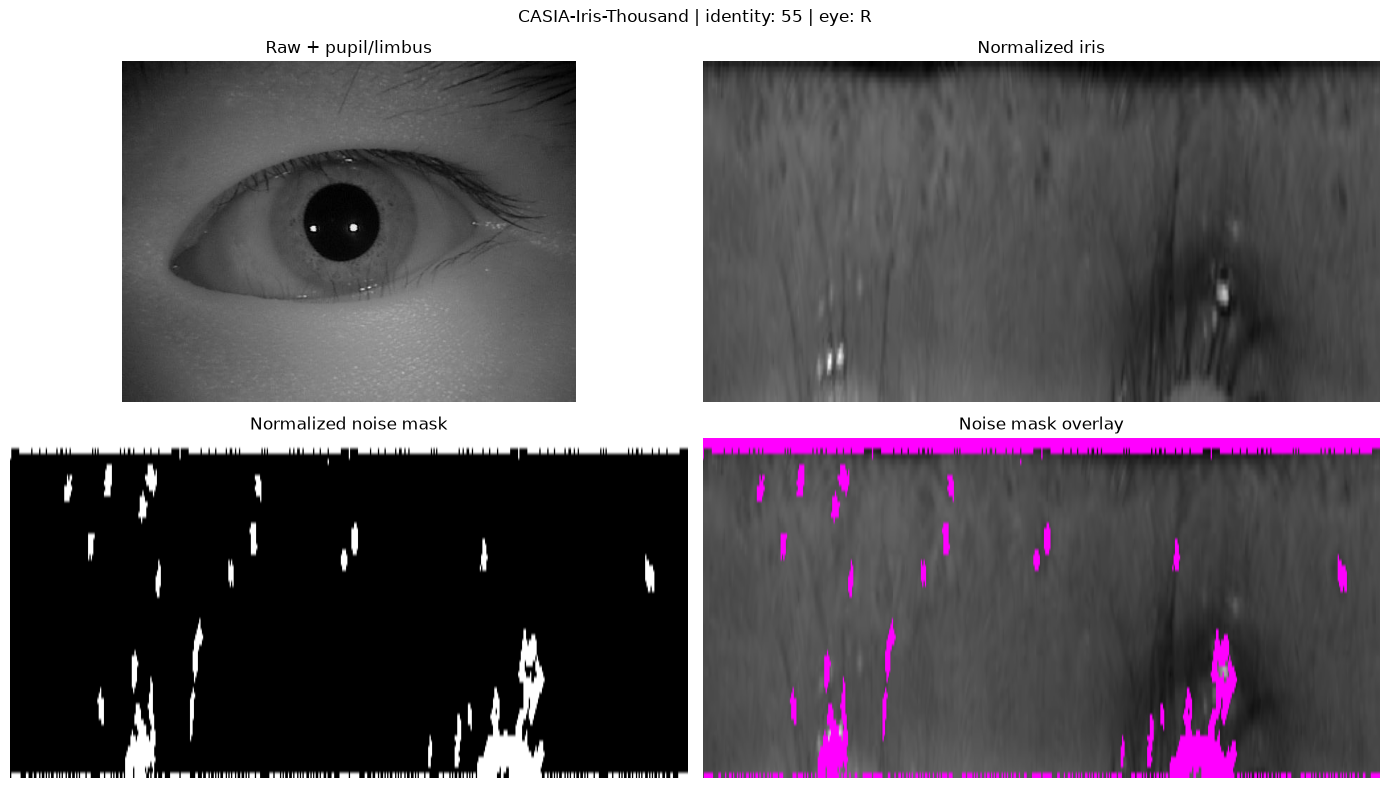

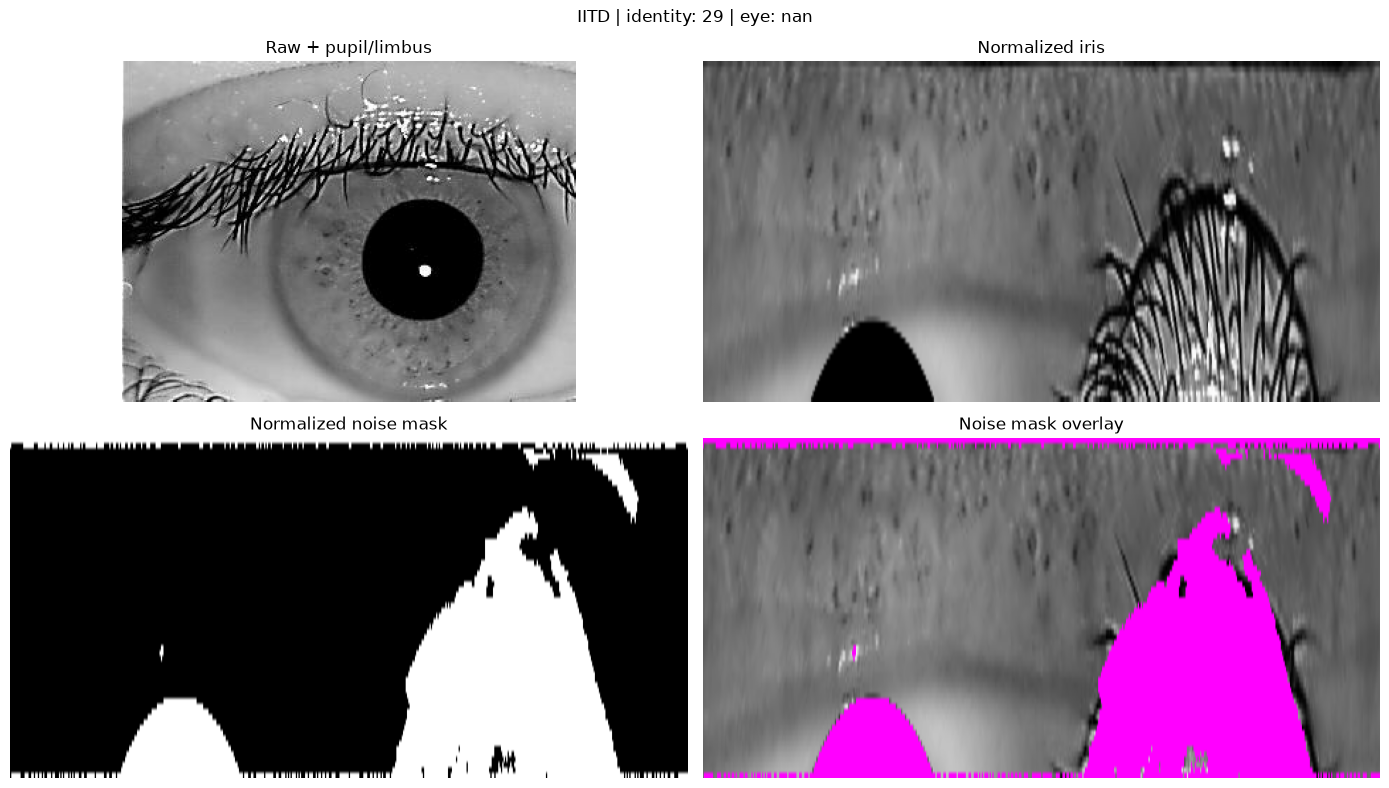

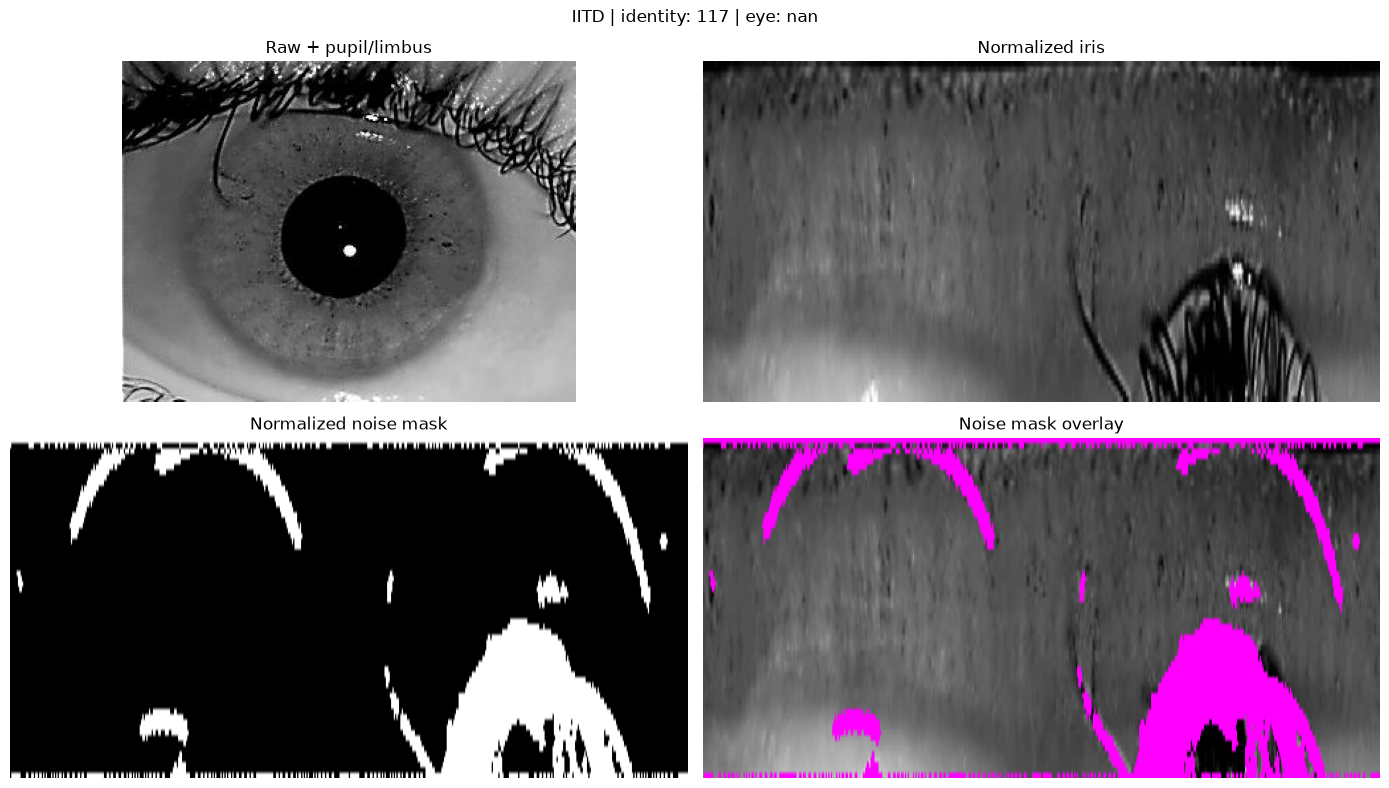

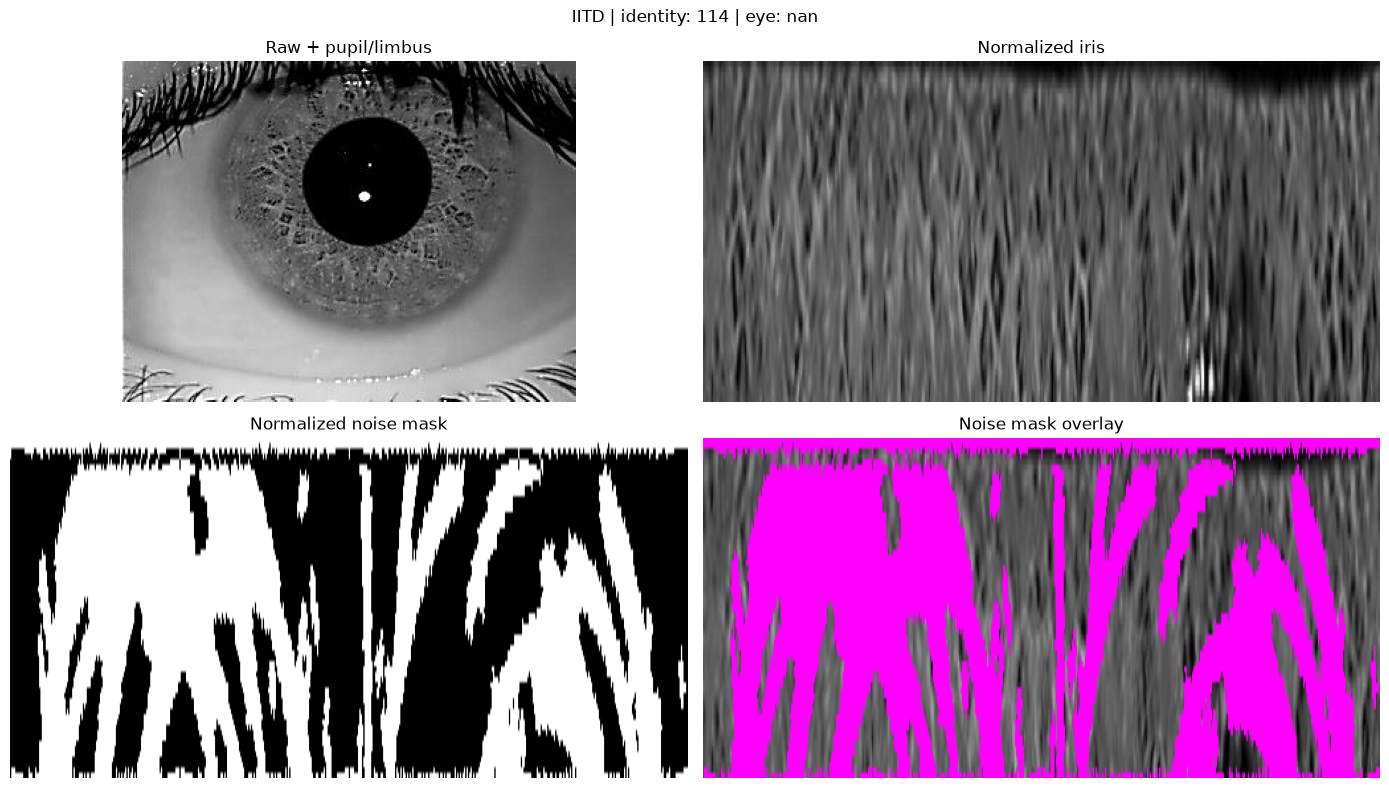

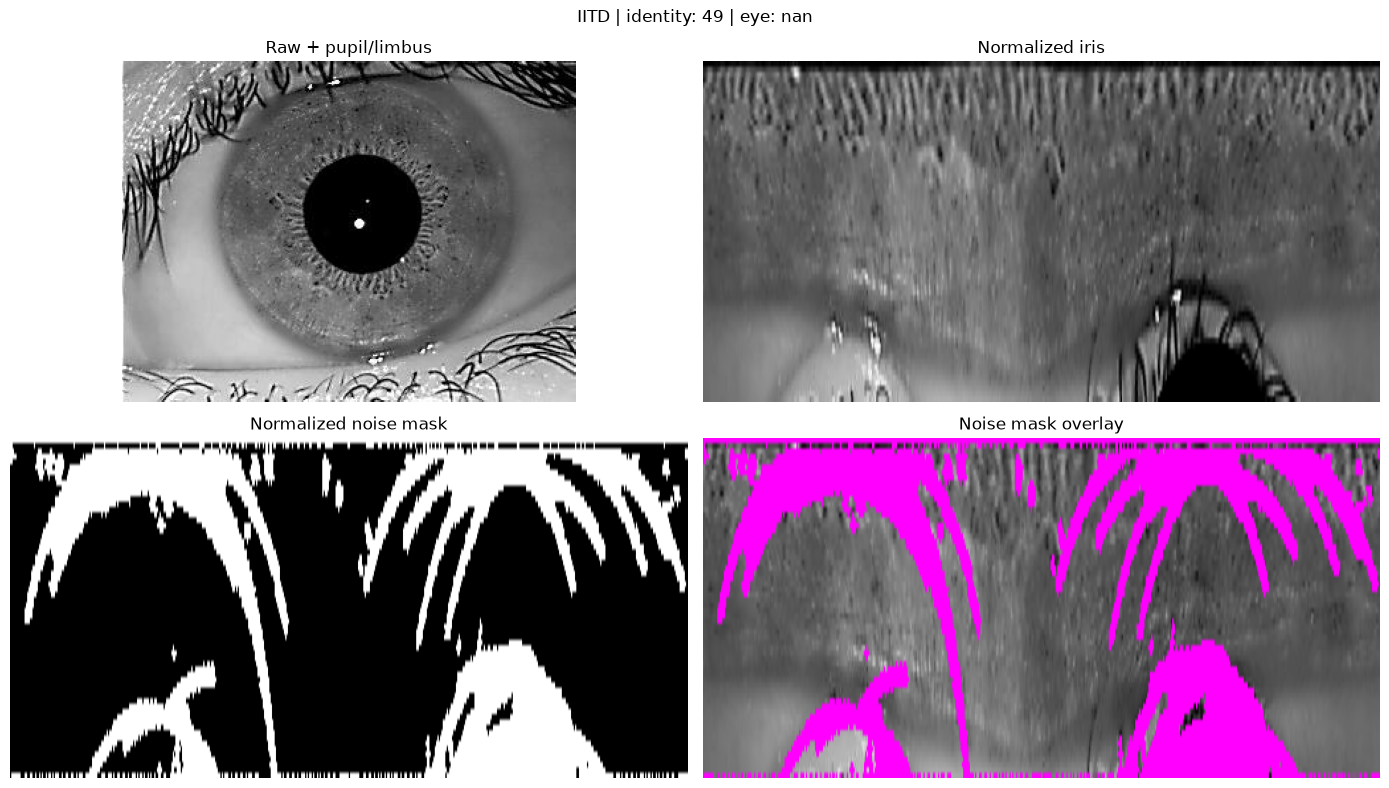

In [17]:
# ============================================================
# 18. Save representative previews
# ============================================================

def create_preview(row):
    gray = safe_read_gray(row["original_path"])

    pupil = circle_from_row(row, "pupil")
    limbus = circle_from_row(row, "limbus")

    vis = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)

    if pupil is not None:
        cv2.circle(
            vis,
            (int(round(pupil["cx"])), int(round(pupil["cy"]))),
            int(round(pupil["radius"])),
            (255, 0, 0),
            2,
        )

    if limbus is not None:
        cv2.circle(
            vis,
            (int(round(limbus["cx"])), int(round(limbus["cy"]))),
            int(round(limbus["radius"])),
            (0, 255, 0),
            2,
        )

    normalized = cv2.imread(str(row["normalized_path"]), cv2.IMREAD_GRAYSCALE)
    noise_mask = cv2.imread(str(row["noise_mask_path"]), cv2.IMREAD_GRAYSCALE)

    overlay = cv2.cvtColor(normalized, cv2.COLOR_GRAY2RGB)
    overlay[noise_mask > 0] = (255, 0, 255)

    fig, axes = plt.subplots(2, 2, figsize=(14, 8))

    axes[0, 0].imshow(vis)
    axes[0, 0].set_title("Raw + pupil/limbus")
    axes[0, 0].axis("off")

    axes[0, 1].imshow(normalized, cmap="gray", aspect="auto")
    axes[0, 1].set_title("Normalized iris")
    axes[0, 1].axis("off")

    axes[1, 0].imshow(noise_mask, cmap="gray", aspect="auto")
    axes[1, 0].set_title("Normalized noise mask")
    axes[1, 0].axis("off")

    axes[1, 1].imshow(overlay, aspect="auto")
    axes[1, 1].set_title("Noise mask overlay")
    axes[1, 1].axis("off")

    plt.suptitle(
        f"{row['dataset']} | identity: {row['identity']} | eye: {row['eye']}",
        fontsize=12,
    )
    plt.tight_layout()

    output_path = (
        PREVIEW_DIR /
        f"{dataset_safe_name(row['dataset'])}_{Path(row['filename']).stem}_preview.png"
    )

    plt.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()

    return output_path


if SAVE_PREVIEWS:
    for dataset_name, df in normalization_metadata.groupby("dataset"):

        successful_df = df[df["success"] == True]

        if len(successful_df) == 0:
            print(f"No successful normalizations to preview for {dataset_name}")
            continue

        preview_sample = successful_df.sample(
            n=min(PREVIEW_COUNT_PER_DATASET, len(successful_df)),
            random_state=RANDOM_SEED,
        )

        # Preview generation can be slow for large samples; limit to a
        # small number of inline plots and rely on the saved PNGs for
        # the remainder.
        for _, row in preview_sample.head(4).iterrows():
            create_preview(row)

## 19. Failure review table

Images that fail normalization (including those that already failed segmentation in Notebook 02) are retained in the metadata rather than silently discarded, for the same reason given in Notebook 02: hidden failures create downstream selection bias in few-shot experiments.


In [18]:
# ============================================================
# 19. Failure review
# ============================================================

failure_table = normalization_metadata[
    ~normalization_metadata["success"]
].copy()

display(
    failure_table[
        [
            "dataset",
            "identity",
            "eye",
            "filename",
            "reason",
        ]
    ].head(50)
)

FAILURE_REPORT_PATH = RESULTS_DIR / "normalization_failures.csv"

failure_table.to_csv(
    FAILURE_REPORT_PATH,
    index=False,
)

print("Saved:", FAILURE_REPORT_PATH)

,dataset,identity,eye,filename,reason
21747,IITD,175,NaN,08_R.bmp,segmentation_failed
22010,IITD,202,NaN,01_L.bmp,segmentation_failed
22011,IITD,202,NaN,02_L.bmp,segmentation_failed
22014,IITD,202,NaN,05_L.bmp,segmentation_failed


Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_normalization\normalization_failures.csv


## 20. Valid-fraction coverage distribution

The `valid_fraction` distribution helps identify normalized images that are dominated by occlusion noise. Very low values may indicate excessive eyelid/eyelash coverage, a poor limbus estimate, or a very small usable iris annulus. This is diagnostic only; final quality-based filtering belongs to a later notebook.


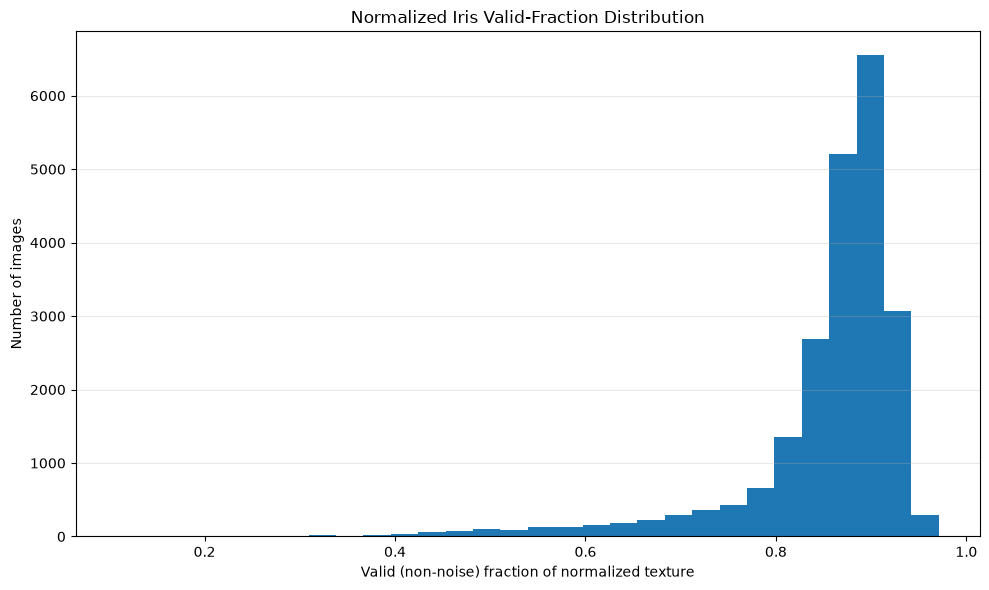

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_normalization\valid_fraction_distribution.png


In [19]:
# ============================================================
# 20. Plot valid-fraction coverage
# ============================================================

plt.figure(figsize=(10, 6))

valid_coverage = normalization_metadata.loc[
    normalization_metadata["success"],
    "valid_fraction",
].dropna()

if len(valid_coverage):
    plt.hist(
        valid_coverage,
        bins=30,
    )

plt.xlabel("Valid (non-noise) fraction of normalized texture")
plt.ylabel("Number of images")
plt.title("Normalized Iris Valid-Fraction Distribution")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

coverage_plot_path = RESULTS_DIR / "valid_fraction_distribution.png"

plt.savefig(
    coverage_plot_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", coverage_plot_path)

## 21. Check normalization output files

Verify that every successful normalization has both a normalized image and a normalized noise mask on disk.


In [20]:
# ============================================================
# 21. Output verification
# ============================================================

def path_exists(path_value):
    '''Safely check whether a stored file path exists.'''

    if pd.isna(path_value):
        return False

    if not isinstance(path_value, (str, Path)):
        return False

    if isinstance(path_value, str) and not path_value.strip():
        return False

    return Path(path_value).exists()


verification_rows = []

for _, row in normalization_metadata.iterrows():

    checks = {
        "normalized_exists": path_exists(row["normalized_path"]),
        "noise_mask_exists": path_exists(row["noise_mask_path"]),
    }

    verification_rows.append(checks)


verification_df = pd.DataFrame(verification_rows)

display(
    verification_df.mean()
    .rename("completion_rate")
    .to_frame()
)

,completion_rate
normalized_exists,0.99982
noise_mask_exists,0.99982


## 22. Final outputs

At the end of Notebook 03, the project should contain:

```text
results/iris_normalization/
├── normalized/
├── noise_masks/
├── previews/
├── normalization_metadata.csv
├── normalization_summary_by_dataset.csv
├── normalization_failures.csv
└── valid_fraction_distribution.png
```

### Main hand-off file

`normalization_metadata.csv` is the critical output for later notebooks. It tells later stages exactly which raw/segmented image produced which normalized texture and normalized noise mask, along with the resolution used and a per-image valid-fraction quality indicator.


In [21]:
# ============================================================
# 22. Final output verification
# ============================================================

print("Notebook 03 output directory:")
print(RESULTS_DIR)

print("\\nTop-level generated files:")
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print(f"- {path.name}")

print("\\nNormalization success rate:")
print(
    f"{normalization_metadata['success'].mean() * 100:.2f}%"
    if len(normalization_metadata)
    else "N/A"
)

print("\\nNotebook 03 completed.")

Notebook 03 output directory:
E:\Research\LargeScale_Synthetic_Iris_Generation\results\iris_normalization
\nTop-level generated files:
- normalization_failures.csv
- normalization_metadata.csv
- normalization_summary_by_dataset.csv
- valid_fraction_distribution.png
\nNormalization success rate:
99.98%
\nNotebook 03 completed.


## 23. What this notebook hands to Notebook 04

Notebook 04 performs **image enhancement** on the normalized iris textures produced here.

The expected hand-off is:

```text
Notebook 01                Notebook 02                  Notebook 03
Raw image + metadata  ---> Segmented iris + masks  ---> Rubber-sheet normalization
                            + boundaries                       |
                                                                 v
                                                    Notebook 04
                                                    Image enhancement
                                                    (CLAHE / histogram
                                                     equalization / etc.)
```

Notebook 03 must therefore remain independent of enhancement: the normalized images saved here are geometrically corrected but photometrically untouched, so that Notebook 04 has a clean, unmodified starting point.

### Important research rule

Do not apply CLAHE, histogram equalization, gamma correction, denoising, or sharpening in this notebook. Those steps belong to Notebook 04 and should be applied to the `normalized_path` images referenced in `normalization_metadata.csv`, using `noise_mask_path` to avoid enhancing occluded regions in a misleading way.
